# Quickstart pipeline: financial time series, end to end

A short, linear notebook to run straight away on a new dataset:

**load → look → target → features → walk-forward CV → baseline / Ridge / LightGBM → test → size predictions → summary**

Edit the **config cell** and run top to bottom. As shipped, it runs on simulated minute-bar prices for two assets, where `B` leads `A`.

- Built for **time-ordered** data (prices, returns, volumes). For non-time-series data, use `00_dataset_interview_playbook.ipynb` instead.
- Everything is past-only and validated walk-forward with a gap, so the numbers are honest.
- The reasoning behind each step is in notebooks 01, 02 and 11.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

from scipy.signal import lfilter
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import TimeSeriesSplit
import lightgbm as lgb

## 0. Config

In [2]:
DATA_PATH = None               # e.g. "data/train.csv"; None = simulated demo data
TIME_COL = "timestamp"
PRICE_COL = "price_a"          # the asset we predict
OTHER_PRICE_COLS = ["price_b"] # other price series used as predictors ([] if none)
VOLUME_COL = "volume"          # None if not available
TARGET_COL = None              # name of a ready-made target column, if the dataset has one; None = build it
HORIZON = 10                   # predict the return over the next HORIZON rows
TEST_SHARE = 0.2               # most recent 20% is the final test set
N_SPLITS = 5

In [3]:
def make_demo(n=20_000):
    # Minute bars: B is a random walk with drifting volatility; A partly follows B's recent moves.
    vol = np.exp(lfilter([0.02], [1, -0.999], rng.normal(size=n)))
    ret_b = vol * rng.normal(size=n)                                   # in basis points
    ret_a = lfilter(np.r_[0, 0.08 * np.exp(-np.arange(1, 21) / 6)], [1], ret_b) + vol * rng.normal(size=n)
    return pd.DataFrame({
        "timestamp": pd.date_range("2024-01-02 09:30", periods=n, freq="1min"),
        "price_a": 100 * np.exp(np.cumsum(ret_a) / 1e4),
        "price_b": 50 * np.exp(np.cumsum(ret_b) / 1e4),
        "volume": rng.lognormal(10, 0.4, n) * vol,
    })

df = pd.read_csv(DATA_PATH) if DATA_PATH else make_demo()
df[TIME_COL] = pd.to_datetime(df[TIME_COL])
df = df.sort_values(TIME_COL).reset_index(drop=True)
df.head()

,timestamp,price_a,price_b,volume
0,2024-01-02 09:30:00,99.9909,49.9917,30307.8842
1,2024-01-02 09:31:00,99.9774,49.9960,19163.7637
2,2024-01-02 09:32:00,99.9804,49.9958,40594.1958
3,2024-01-02 09:33:00,99.9816,49.9927,14994.1631
4,2024-01-02 09:34:00,99.9591,49.9915,11023.0590


## 1. Quick checks

In [4]:
print(f"rows: {len(df):,} | from {df[TIME_COL].min()} to {df[TIME_COL].max()}")
miss = df.isna().sum()
print("missing values:", dict(miss[miss > 0]) or "none")
print("duplicated timestamps:", df[TIME_COL].duplicated().sum())
step = df[TIME_COL].diff()
print("typical time step:", step.median(), "| gaps > 5x typical:", (step > 5 * step.median()).sum())
print("non-positive prices:", (df[[PRICE_COL, *OTHER_PRICE_COLS]] <= 0).sum().sum())

rows: 20,000 | from 2024-01-02 09:30:00 to 2024-01-16 06:49:00
missing values: none
duplicated timestamps: 0
typical time step: 0 days 00:01:00 | gaps > 5x typical: 0
non-positive prices: 0


Gaps (overnight, weekends, missing data) matter: a return spanning a gap isn't comparable to a normal one-step return. If there are many, add a session id and reset features at each session start.

## 2. Introductory plots

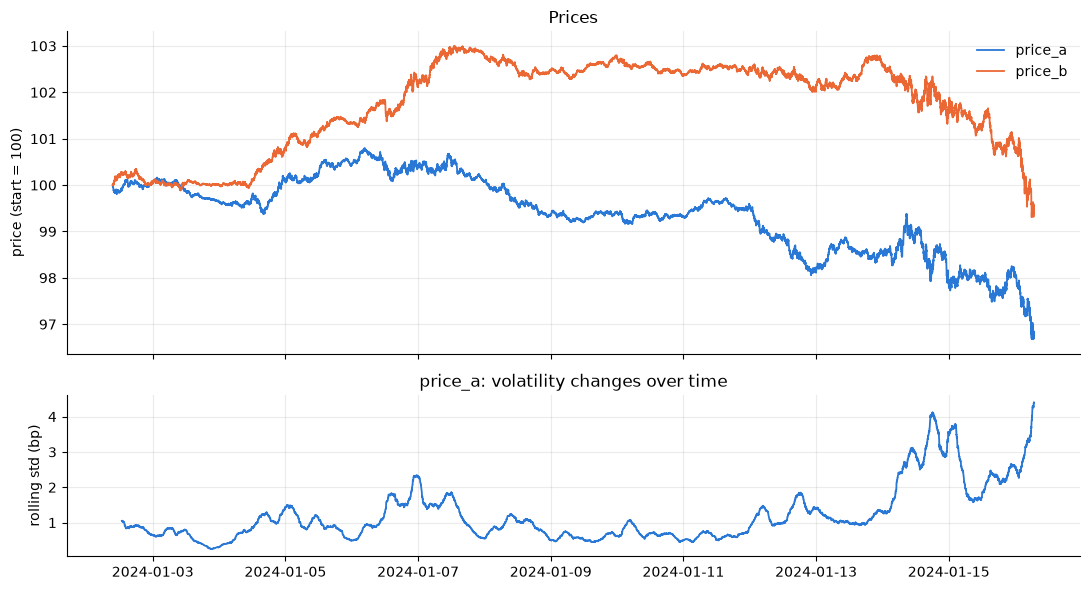

In [5]:
prices = [PRICE_COL, *OTHER_PRICE_COLS]
rets = np.log(df[prices]).diff() * 1e4                 # log returns in basis points
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for i, c in enumerate(prices[:4]):
    axes[0].plot(df[TIME_COL], df[c] / df[c].iloc[0] * 100, color=PALETTE[i], lw=1.3, label=c)
axes[0].set_ylabel("price (start = 100)"); axes[0].legend(); axes[0].set_title("Prices")
axes[1].plot(df[TIME_COL], rets[PRICE_COL].rolling(200).std(), color=PALETTE[0], lw=1.3)
axes[1].set_ylabel("rolling std (bp)"); axes[1].set_title(f"{PRICE_COL}: volatility changes over time")
plt.tight_layout()
plt.show()

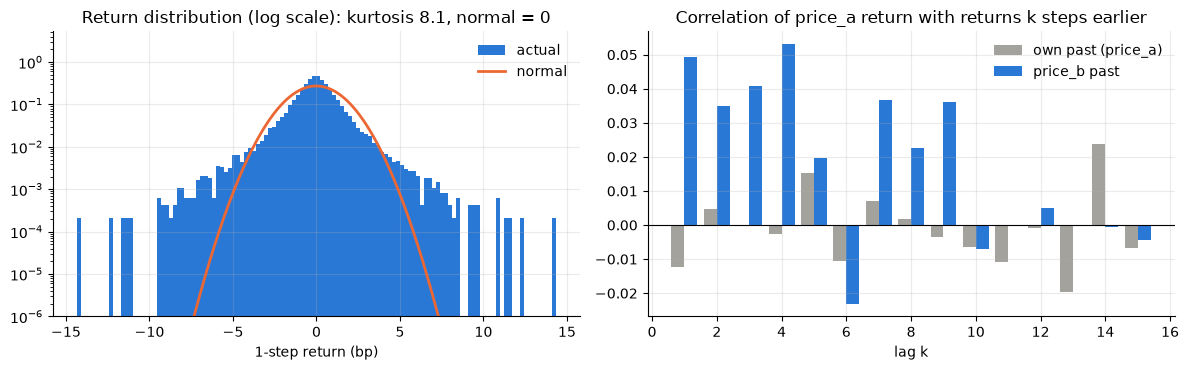

In [6]:
r = rets[PRICE_COL].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(r, bins=120, color=PALETTE[0], density=True, log=True, label="actual")
xs = np.linspace(r.min(), r.max(), 300)
axes[0].plot(xs, np.exp(-0.5 * ((xs - r.mean()) / r.std()) ** 2) / (r.std() * np.sqrt(2 * np.pi)), color=PALETTE[1], label="normal")
axes[0].set_ylim(bottom=1e-6); axes[0].legend()
axes[0].set_title(f"Return distribution (log scale): kurtosis {r.kurt():.1f}, normal = 0"); axes[0].set_xlabel("1-step return (bp)")

lags = range(1, 16)
own = [r.corr(r.shift(k)) for k in lags]
axes[1].bar([k - 0.2 for k in lags], own, width=0.4, color=GREY, label=f"own past ({PRICE_COL})")
if OTHER_PRICE_COLS:
    other = rets[OTHER_PRICE_COLS[0]]
    axes[1].bar([k + 0.2 for k in lags], [r.corr(other.shift(k)) for k in lags], width=0.4, color=PALETTE[0], label=f"{OTHER_PRICE_COLS[0]} past")
axes[1].axhline(0, color="black", lw=0.8); axes[1].legend()
axes[1].set(title=f"Correlation of {PRICE_COL} return with returns k steps earlier", xlabel="lag k")
plt.tight_layout()
plt.show()

What to look for: fat tails (clip or use robust losses), volatility regimes (scale features by volatility), and **any lag with a correlation clearly away from 0**. Here A's own past says nothing, while B's recent moves lead A.

## 3. Target
The return over the next `HORIZON` rows, built with `shift(-HORIZON)`. It's the only place future data is allowed.

In [7]:
logp = np.log(df[PRICE_COL])
df["target"] = df[TARGET_COL] if TARGET_COL else (logp.shift(-HORIZON) - logp) * 1e4
print(df["target"].describe().round(2).to_string())

count    19990.00
mean        -0.16
std          4.61
min        -39.65
25%         -2.09
50%         -0.11
75%          1.95
max         30.43


## 4. Features (past-only)
Every feature at row *t* uses data up to *t* only: lags, trailing windows, exponentially-weighted averages. Momentum is divided by recent volatility, so a move is judged relative to what's normal *right now*.

In [8]:
def make_features(d):
    f = pd.DataFrame(index=d.index)
    for c in prices:
        ret = np.log(d[c]).diff() * 1e4
        vol = ret.rolling(100, min_periods=20).std()
        f[f"{c}_ret_1"] = ret
        for hl in [2, 8, 32]:
            f[f"{c}_mom_{hl}"] = ret.ewm(halflife=hl, adjust=False).mean() / vol    # vol-scaled momentum
        f[f"{c}_vol_100"] = vol
    for c in OTHER_PRICE_COLS:                                                     # relative value: spread z-score
        spread = np.log(d[PRICE_COL]) - np.log(d[c])
        f[f"spread_z_{c}"] = (spread - spread.rolling(60).mean()) / spread.rolling(60).std()
    if VOLUME_COL:
        lv = np.log(d[VOLUME_COL])
        f["volume_z"] = (lv - lv.rolling(100).mean()) / lv.rolling(100).std()
    return f

feats = make_features(df)
data = pd.concat([df[[TIME_COL, "target"]], feats], axis=1).dropna().reset_index(drop=True)
FEATURES = list(feats.columns)
print(f"{len(FEATURES)} features, {len(data):,} usable rows")

12 features, 19,891 usable rows


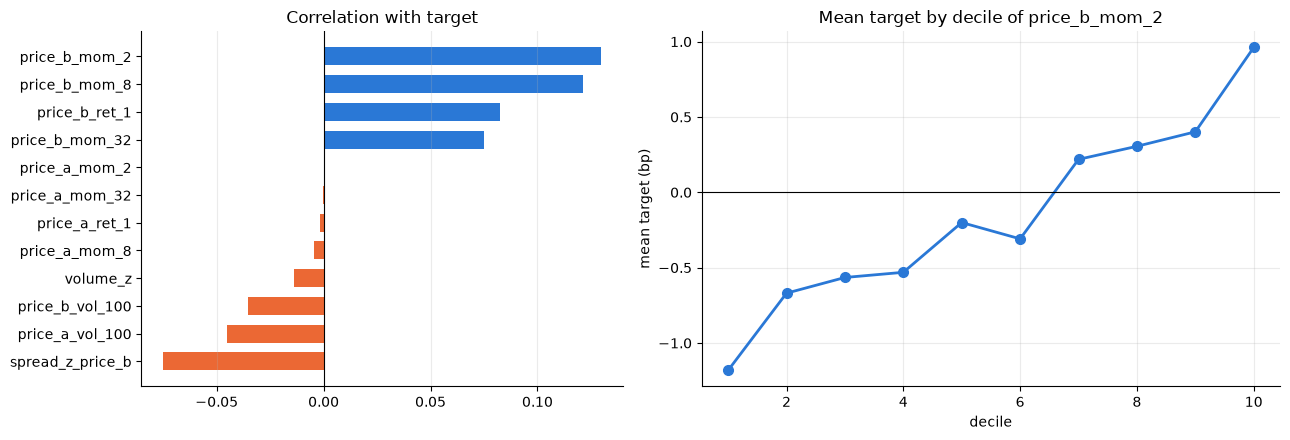

In [9]:
corr = data[FEATURES].corrwith(data["target"]).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].barh(corr.index, corr.values, color=[PALETTE[0] if v > 0 else PALETTE[1] for v in corr.values], height=0.65)
axes[0].axvline(0, color="black", lw=0.8); axes[0].set_title("Correlation with target"); axes[0].grid(axis="y", visible=False)

top = corr.abs().idxmax()
dec = pd.qcut(data[top].rank(method="first"), 10, labels=False) + 1
axes[1].plot(range(1, 11), data.groupby(dec)["target"].mean(), "o-", color=PALETTE[0], ms=7)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title=f"Mean target by decile of {top}", xlabel="decile", ylabel="mean target (bp)")
plt.tight_layout()
plt.show()

A **straight line** across the deciles means a linear model will capture it. Curves or plateaus mean try boosting or transform the feature.

## 5. Split: train for model building, most recent period for the final test

In [10]:
n_test = int(len(data) * TEST_SHARE)
train = data.iloc[: len(data) - n_test - HORIZON]       # drop HORIZON rows so no training target overlaps the test period
test = data.iloc[len(data) - n_test:]
X_tr, y_tr, X_te, y_te = train[FEATURES], train["target"], test[FEATURES], test["target"]
print(f"train: {train[TIME_COL].min()} -> {train[TIME_COL].max()}  ({len(train):,} rows)")
print(f"test : {test[TIME_COL].min()} -> {test[TIME_COL].max()}  ({len(test):,} rows)")

cv = TimeSeriesSplit(n_splits=N_SPLITS, gap=HORIZON)    # walk-forward inside the training period

train: 2024-01-02 11:09:00 -> 2024-01-13 12:11:00  (15,903 rows)
test : 2024-01-13 12:22:00 -> 2024-01-16 06:39:00  (3,978 rows)


## 6. Models, compared walk-forward on the same folds
- **Predict zero:** the benchmark for returns.
- **Ridge:** standardised features; the penalty is chosen by walk-forward CV *inside* each training window (`cv=` is set, so no leave-one-out leak).
- **LightGBM:** heavily regularised (few leaves, large leaves) because the signal is weak.

In [11]:
models = {
    "predict zero": DummyRegressor(strategy="constant", constant=0.0),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 5, 30), cv=TimeSeriesSplit(3, gap=HORIZON))),
    "LightGBM": lgb.LGBMRegressor(n_estimators=300, learning_rate=0.02, num_leaves=7, min_child_samples=300,
                                  subsample=0.7, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
}

def r2_vs_zero(y, p):
    return 1 - np.mean((y - p) ** 2) / np.mean(y ** 2)

rows, oof = [], {}
for name, model in models.items():
    pred = pd.Series(np.nan, index=y_tr.index)
    fold_r2 = []
    for tr, va in cv.split(X_tr):
        model.fit(X_tr.iloc[tr], y_tr.iloc[tr])
        pred.iloc[va] = model.predict(X_tr.iloc[va])
        fold_r2.append(r2_vs_zero(y_tr.iloc[va].values, pred.iloc[va].values))
    oof[name] = pred
    m = pred.notna()
    rows.append({"model": name, **{f"fold {i+1}": v for i, v in enumerate(fold_r2)},
                 "mean R² vs 0 (%)": 100 * np.mean(fold_r2), "corr": np.corrcoef(pred[m], y_tr[m])[0, 1] if pred[m].std() > 0 else 0})
cv_table = pd.DataFrame(rows).set_index("model")
cv_table.style.format({c: "{:+.4f}" for c in cv_table.columns if c.startswith("fold")} | {"mean R² vs 0 (%)": "{:+.2f}", "corr": "{:.3f}"})

,fold 1,fold 2,fold 3,fold 4,fold 5,mean R² vs 0 (%),corr
model,,,,,,,
predict zero,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.00,0.000
Ridge,+0.0099,-0.0040,+0.0174,+0.0340,+0.0341,+1.83,0.126
LightGBM,-0.0164,-0.0100,+0.0150,+0.0169,+0.0105,+0.32,0.109


Small R² is normal for returns: 1% of variance explained is a real edge. Look at **every fold**: an edge that only exists in one period isn't one.

## 7. Size the predictions
The best scale for predictions is the out-of-sample slope of actual on predicted, $c^* = \frac{E[\hat y\, y]}{E[\hat y^2]}$ (notebook 02, section 7). It's estimated from the walk-forward predictions only, never from the test set.

In [12]:
best = cv_table.drop("predict zero")["mean R² vs 0 (%)"].idxmax()
m = oof[best].notna()
c_star = float(np.sum(oof[best][m] * y_tr[m]) / np.sum(oof[best][m] ** 2))
print(f"best model in CV: {best} | prediction scale c* = {c_star:.2f}  (1 = sized right, <1 = overconfident)")

best model in CV: Ridge | prediction scale c* = 1.03  (1 = sized right, <1 = overconfident)


## 8. Final test: fit on the whole training period, evaluate once

In [13]:
test_rows, test_pred = {}, {}
for name, model in models.items():
    model.fit(X_tr, y_tr)
    test_pred[name] = model.predict(X_te)
test_pred[f"{best} × c*"] = c_star * test_pred[best]
for name, p in test_pred.items():
    test_rows[name] = {"R² vs 0 (%)": 100 * r2_vs_zero(y_te.values, p),
                       "corr": np.corrcoef(p, y_te)[0, 1] if np.std(p) > 0 else 0.0,
                       "hit rate (sign)": np.mean(np.sign(p) == np.sign(y_te)) if np.std(p) > 0 else np.nan}
test_table = pd.DataFrame(test_rows).T
test_table.style.format({"R² vs 0 (%)": "{:+.2f}", "corr": "{:.3f}", "hit rate (sign)": "{:.3f}"})

,R² vs 0 (%),corr,hit rate (sign)
predict zero,+0.00,0.000,nan
Ridge,+1.44,0.111,0.562
LightGBM,+1.23,0.107,0.562
Ridge × c*,+1.46,0.111,0.562


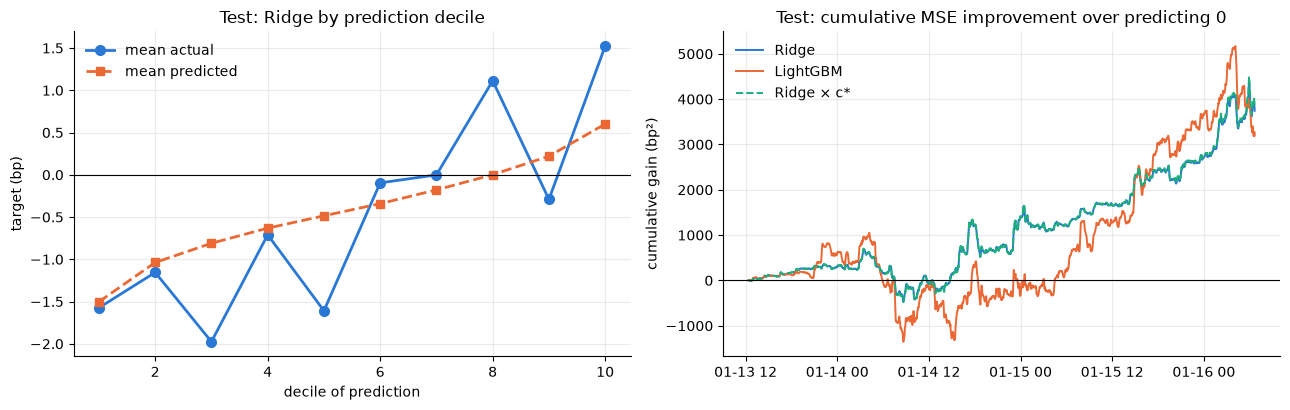

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
p = test_pred[best]
dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False).values + 1
g = pd.DataFrame({"pred": p, "actual": y_te.values}).groupby(dec).mean()
axes[0].plot(g.index, g["actual"], "o-", color=PALETTE[0], ms=7, label="mean actual")
axes[0].plot(g.index, g["pred"], "s--", color=PALETTE[1], ms=6, label="mean predicted")
axes[0].axhline(0, color="black", lw=0.8); axes[0].legend()
axes[0].set(title=f"Test: {best} by prediction decile", xlabel="decile of prediction", ylabel="target (bp)")

for i, name in enumerate([n for n in test_pred if n != "predict zero"]):
    gain = (y_te.values ** 2 - (y_te.values - test_pred[name]) ** 2).cumsum()
    axes[1].plot(test[TIME_COL], gain, color=PALETTE[i], lw=1.4, label=name, ls="--" if "c*" in name else "-")
axes[1].axhline(0, color="black", lw=0.8); axes[1].legend()
axes[1].set(title="Test: cumulative MSE improvement over predicting 0", ylabel="cumulative gain (bp²)")
plt.tight_layout()
plt.show()

The right-hand plot shows **when** the model earns its edge. A steady upward line is what you want; a single jump means one episode drives the result.

## 9. What drives the model

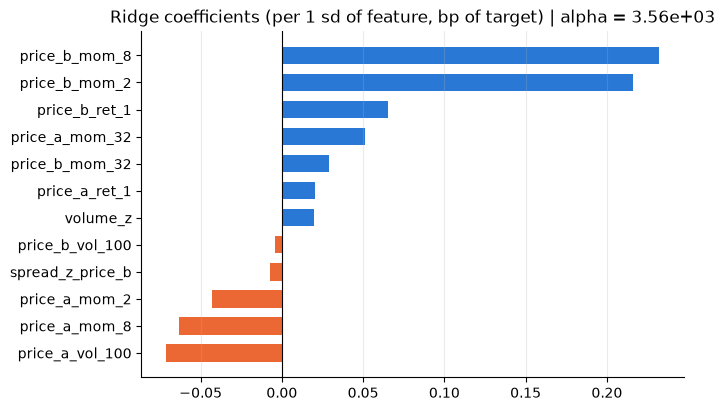

In [15]:
ridge = models["Ridge"]
coefs = pd.Series(ridge[-1].coef_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(coefs.index, coefs.values, color=[PALETTE[0] if v > 0 else PALETTE[1] for v in coefs.values], height=0.65)
ax.axvline(0, color="black", lw=0.8); ax.grid(axis="y", visible=False)
ax.set_title(f"Ridge coefficients (per 1 sd of feature, bp of target) | alpha = {ridge[-1].alpha_:.3g}")
plt.show()

## 10. Summary for the slides

In [16]:
print(f"Data: {len(df):,} rows, {df[TIME_COL].min():%Y-%m-%d} to {df[TIME_COL].max():%Y-%m-%d}; target = {HORIZON}-step forward return of {PRICE_COL}")
print(f"Validation: walk-forward, {N_SPLITS} folds, gap {HORIZON}; final test = last {TEST_SHARE:.0%}")
print(f"Features: {len(FEATURES)}; strongest single feature: {corr.abs().idxmax()} (corr {corr[corr.abs().idxmax()]:+.3f})")
print("\nWalk-forward CV (R² vs predicting 0, %):")
print(cv_table["mean R² vs 0 (%)"].round(2).to_string())
print(f"\nChosen: {best}, predictions scaled by c* = {c_star:.2f}")
print("Test:")
print(test_table.round(4).to_string())

Data: 20,000 rows, 2024-01-02 to 2024-01-16; target = 10-step forward return of price_a
Validation: walk-forward, 5 folds, gap 10; final test = last 20%
Features: 12; strongest single feature: price_b_mom_2 (corr +0.130)

Walk-forward CV (R² vs predicting 0, %):
model
predict zero    0.00
Ridge           1.83
LightGBM        0.32

Chosen: Ridge, predictions scaled by c* = 1.03
Test:
              R² vs 0 (%)    corr  hit rate (sign)
predict zero       0.0000  0.0000              NaN
Ridge              1.4429  0.1112           0.5616
LightGBM           1.2331  0.1072           0.5623
Ridge × c*         1.4607  0.1112           0.5616


## Where to go next (if time allows)
- **Feature ideas:** other horizons/half-lives, cross-asset lags, intraday seasonality (time of day), volume-weighted moves, resetting features at session starts.
- **Robustness:** results by month or regime; a placebo test (shift the target by a large amount and check the edge vanishes); different `HORIZON` values.
- **Many assets (panel data):** compute features per asset with `groupby(asset).transform(...)`, and keep the split by *time* so all assets on a date sit on the same side.
- **Risk of overfitting:** every idea tried on the same folds inflates the CV score. Keep the test set for the end, and say what you tried.